# Unit Search: 4-Task Multi-MNIST

Can a network that grows and prunes whole units, starting from nothing and held to a fixed connection budget, find
connectivity as good as the ideal network's? The budget, 19,080 connections, is what the ideal network uses: too few for
random connectivity to do well, enough for the right connectivity to come close to a dense network.

**Problem.** 4-task multi-MNIST. Each sample concatenates 4 independently drawn 28×28 MNIST training images (3,136
inputs), and each task's target is its own image's label (40 outputs, 4 groups of 10 logits). Every 500 steps, one task
chosen at random gets a new random mapping from digits to labels. The loss is the sum of the tasks' softmax
cross-entropies; plots show it averaged over tasks.

**Network.** Inputs → one hidden layer of LTUs (sigmoid surrogate derivative) → linear outputs. Every hidden unit and
output has a bias. Pixels and hidden units are standardized online, $h = (b - m)/\sqrt{\max(s, 0.01)}$, with a running
mean $m$ and variance $s$ (rate 0.001). Pixel statistics start at the training set's values. For a hidden unit,
$s = m(1 - m)$ and $m$ starts at 1/2; its backward pass accounts for the statistics' dependence on the weights (as in
`phd/sandbox/incremental_generalization/02_two_layer_recurring_tasks.ipynb`).

**Learner.** Network Autostep: Autostep (`squared_inputs`, meta step-size 0.01, $\tau = 10^4$), every step-size
starting at $\alpha_0 = 10^{-4}$, input weights $U(-\alpha_0, \alpha_0)$, biases and output weights 0. Autostep's
per-row normalization counts only existing connections. Every weight (biases excluded) has L1 regularization with
coefficient 0.01: its subgradient is added to the loss gradient that Autostep learns from.

**Search.** The network starts with no hidden units. The budget counts every hidden unit's inputs, bias and outputs.
The structure changes every 20 steps, in this order:
1. *Utility.* Each unit's utility is a trace (rate 0.001 per step) of its summed |output weight| divided by its number
   of connections (inputs, bias and outputs).
2. *Connection pruning.* A connection whose weight crossed zero since the last structure change is pruned if its
   step-size is below $\alpha_0/2$. Biases are never pruned.
3. *Dead units.* A unit left with no inputs or no outputs is removed.
4. *Unit pruning.* The lowest-utility units are pruned at the prune rate: each step adds prune rate × number of units to
   a running count, and a unit is pruned for every whole unit it holds.
5. *Generation.* New units fill the free budget. Each reads 128 random inputs and feeds 20 random outputs (149
   connections with its bias), and its utility starts at the median of the existing units'. One of its outputs, chosen at
   random, carries a fixed ±1 shadow weight: the unit's error comes from every output through the real output weights,
   except that the paired output's weight counts as the shadow weight unless the real one is larger in magnitude. If
   that connection is pruned, the shadow weight goes with it.

`UNIT_SEARCH = False` turns off steps 4 and 5 once the budget has first been filled, so after the first fill only
connections are pruned (and units left without inputs or outputs removed).

**Runs.** 1M steps, 5 seeds; seed $s$ gives every run the same initial weights, images and label changes.
- *Search* (proposed), at prune rates 0, $10^{-6}$, $10^{-5}$, $10^{-4}$ and $10^{-3}$; with `UNIT_SEARCH = False`,
  a single run.
- *Random sparse* (baseline): search with nothing pruned, so the 128 random units of the first fill stay as they are.
- *Ideal connectivity* (reference): 6 units per task, each reading all 784 of its task's pixels and feeding its task's
  10 outputs (19,080 connections).
- *Dense* (reference): 6 units, each reading every pixel and feeding every output (19,062 connections).

The references are network Autostep alone: fixed connectivity, no shadow weights.

**Hypotheses**, on the online loss over the last 10% of training, averaged over seeds, for search at its best prune
rate:
- **H1**: search is within 1% of ideal connectivity.
- **H2**: search is more than 1% below random sparse.

**Diagnostics**, for search and random sparse:
- *Path purity*: the share of input → hidden → output paths through existing connections (biases left out) that start
  and end in the same task.
- *Fan-in*: connections into each hidden unit (from inputs) and into each output (from hidden units), biases
  left out.
- *Units*: how many exist, and how many have been removed (dead or pruned) and generated so far.

Everything is recorded at step 1, then averaged over windows of 5,000 steps (the diagnostics are sampled at every
structure change). Curves are means over seeds.

## Points to address later

- **New units are likely pruned before they mature.** A new unit costs 149 connections. Once connection pruning has
  removed its other tasks' connections (about 3/4 of them), it costs about 40, so at equal output weights a newborn's
  utility is about 4× lower. Its median head start wears off within a few thousand steps, while a connection is only
  pruned once its step-size has drifted below half its initial value, likely 100k steps or more. So utility pruning
  will mostly remove the newest units, the incumbency problem of the earlier unit-level search. Age protection
  (`MATURITY_AGE` of about 100k) is one fix.
- **Rarely lit pixels hold budget forever.** 67 of the 784 MNIST pixels are never lit, and 189 are lit less than 0.1%
  of the time. Their connections get almost no gradient, so they never cross zero and are never pruned. That is about
  31 of every new unit's 128 inputs, which also dilute its utility.
- **Small units may be the limit, not the search.** Units only lose inputs, so a mature unit reads about 32 of its
  task's pixels, against 784 for an ideal-connectivity unit. If search falls short of ideal connectivity, the cause may
  be the small units rather than the search. A fixed network of such units (32 random pixels from one task, feeding
  that task's outputs) would tell the two apart.

In [1]:
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS, N_PIXELS, N_CLASSES = 4, 28 * 28, 10
N_INPUTS, N_OUTPUTS = N_TASKS * N_PIXELS, N_TASKS * N_CLASSES
PERMUTE_PERIOD = 500                 # steps between label changes, each of one task chosen at random

# --- Network and learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of pixels and hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size, also the scale of the initial input weights
META_STEP_SIZE, TAU = 0.01, 1e4
L1 = 0.001                            # L1 regularization of every weight (not biases), in Autostep's gradient

# --- Search ---
BUDGET = 19_080                      # connections (hidden units' inputs, biases and outputs): the ideal network's
FAN_IN, FAN_OUT = 128, 20            # a new unit's random inputs and outputs
UNIT_COST = FAN_IN + 1 + FAN_OUT     # a new unit's connections, with its bias
UNIT_SEARCH = True                   # False: no unit pruning, and no new units once the budget is first filled
RESTRUCTURE_PERIOD = 20              # steps between structure changes
UTILITY_RATE = 1e-3                  # per step
PRUNE_RATES = (0.0, 1e-6, 1e-5, 1e-4) if UNIT_SEARCH else (0.0,)   # units pruned per unit per step
MATURITY_AGE = 0                     # units younger than this (in steps) are never pruned for low utility; 0 = off
MAX_UNITS, MAX_NEW_UNITS = 256, 8    # unit slots, and units added per structure change at most

# --- Training ---
NUM_STEPS = 2_000_000
N_SEEDS = 5
N_WINDOWS = 200                      # each window records the mean of every recorded value
FINAL_FRACTION = 0.1                 # the hypotheses compare the loss over the last 10% of training ...
TOLERANCE = 0.01                     # ... relative to this (1%)

## Problem

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
IMAGES = jnp.asarray(np.asarray(mnist.data, dtype=np.float32).reshape(-1, N_PIXELS) / 255.0)
DIGITS = jnp.asarray(np.asarray(mnist.targets))
INPUT_TASK = jnp.arange(N_INPUTS) // N_PIXELS
OUTPUT_TASK = jnp.arange(N_OUTPUTS) // N_CLASSES


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

## Networks

A network is stored per hidden unit: `sources` lists the inputs each unit reads, `w1` holds the matching weights (its
last column is the bias), and `w2` is the output weight matrix (its last column is the output biases). Masks mark which
connections exist; a unit exists while its bias does.

In [4]:
def search_network():
    # No hidden units yet: only the output biases exist.
    return jnp.zeros((MAX_UNITS, FAN_IN), int), {'w1': jnp.zeros((MAX_UNITS, FAN_IN + 1), bool),
                                                 'w2': jnp.zeros((N_OUTPUTS, MAX_UNITS + 1), bool).at[:, -1].set(True)}


def ideal_network(units_per_task=6):
    # Each unit reads all of its task's pixels and feeds only its task's outputs.
    unit_task = jnp.repeat(jnp.arange(N_TASKS), units_per_task)
    feeds = jnp.concatenate([OUTPUT_TASK[:, None] == unit_task[None], jnp.ones((N_OUTPUTS, 1), bool)], axis=1)
    return unit_task[:, None] * N_PIXELS + jnp.arange(N_PIXELS), {'w1': jnp.ones((len(unit_task), N_PIXELS + 1), bool),
                                                                  'w2': feeds}


def dense_network(n_units=6):
    # Every unit reads every pixel and feeds every output.
    return jnp.tile(jnp.arange(N_INPUTS), (n_units, 1)), {'w1': jnp.ones((n_units, N_INPUTS + 1), bool),
                                                          'w2': jnp.ones((N_OUTPUTS, n_units + 1), bool)}


for name, network in [('ideal', ideal_network()), ('dense', dense_network())]:
    print(f'{name}: {int(network[1]["w1"].sum() + network[1]["w2"][:, :-1].sum()):,} connections')

ideal: 19,080 connections
dense: 19,062 connections


## Learner

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')
PIXEL_MEAN = jnp.tile(IMAGES.mean(0), N_TASKS)
PIXEL_VAR = jnp.tile(IMAGES.var(0), N_TASKS)


class Config(NamedTuple):
    prune_rate: float           # units pruned for low utility, per unit per step
    prune_connections: bool     # whether connections that cross zero are pruned


class Learner(NamedTuple):
    w: dict                     # {'w1': (unit, fan-in + 1), 'w2': (output, unit + 1)}; last columns are biases
    mask: dict                  # which connections exist, shaped like w
    sources: jax.Array          # (unit, fan-in): the input each of a unit's input weights reads
    crossed: dict               # which weights crossed zero since the last structure change, shaped like w
    opt: IDBDState
    pixel_mean: jax.Array       # running statistics of each pixel ...
    pixel_var: jax.Array
    hidden_mean: jax.Array      # ... and each hidden unit's running firing rate
    error_mean: jax.Array       # running means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array
    shadow_output: jax.Array    # the output each unit's shadow weight pairs it with ...
    shadow_sign: jax.Array      # ... and the shadow weight's fixed value, +-1
    utility: jax.Array
    age: jax.Array
    prune_count: jax.Array      # units owed to unit pruning, carried until a whole unit is due
    filled: jax.Array           # whether the budget has been filled once


def init_learner(key, network):
    # Input weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE); biases and output weights 0.
    sources, mask = network
    n_units = len(sources)
    w1 = jax.random.uniform(key, mask['w1'].shape, minval=-INIT_STEP_SIZE, maxval=INIT_STEP_SIZE).at[:, -1].set(0.0)
    w = {'w1': w1 * mask['w1'], 'w2': jnp.zeros(mask['w2'].shape)}
    zeros = jnp.zeros(n_units)
    crossed = jax.tree.map(jnp.zeros_like, mask)
    return Learner(w, mask, sources, crossed, OPTIMIZER.init(w), PIXEL_MEAN, PIXEL_VAR, jnp.full(n_units, 0.5), zeros,
                   zeros, jnp.zeros(n_units, int), jnp.ones(n_units), zeros, jnp.zeros(n_units, int), jnp.array(0.0),
                   jnp.array(False))

For $h = (b - \mu)/\sigma$ with $\mu = E[b]$ and $\sigma^2 = E[(b - \mu)^2]$, the gradient of the expected loss with
respect to $b$ is $(g - E[g] - h\,E[g h])/\sigma$, where $g$ is the error arriving at $h$. The custom backward of
`standardize` uses running means of $g$ and $g h$ (rate 0.001). When the variance floor is active, $\sigma$ is constant
and the $h\,E[g h]$ term drops.

In [6]:
@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


def predict(w, probe, learner, x, fixed):
    # Returns the logits, each weight's source values (what Autostep normalizes by), the hidden values and the new
    # running statistics. Statistics move toward this sample before they are used. `probe` is zero; its gradient is the
    # error arriving at each hidden unit.
    pixel_mean = learner.pixel_mean + STAT_RATE * (x - learner.pixel_mean)
    pixel_var = learner.pixel_var + STAT_RATE * ((x - pixel_mean) ** 2 - learner.pixel_var)
    x = (x - pixel_mean) / jnp.sqrt(jnp.maximum(pixel_var, VAR_FLOOR))

    inputs = jnp.concatenate([x[learner.sources], jnp.ones((len(learner.sources), 1))], axis=1)
    bits = ltu(jnp.sum(w['w1'] * learner.mask['w1'] * inputs, axis=1))
    hidden_mean = learner.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(bits) - learner.hidden_mean)
    h = standardize(bits, hidden_mean, learner.error_mean, learner.error_h_mean)
    a = h + probe

    w2 = w['w2'] * learner.mask['w2']
    if fixed:
        logits = w2 @ jnp.append(a, 1.0)
    else:
        # Shadow weights: the outputs read the hidden units as usual, but the error reaching them comes through
        # `feedback`, the output weights with each unit's paired weight replaced by its shadow weight unless the real one
        # is larger in magnitude. The last two terms cancel in value, and the output weights keep their true gradient.
        units = jnp.arange(len(h))
        real = w2[learner.shadow_output, units]
        paired = learner.mask['w2'][learner.shadow_output, units]
        shadow = jnp.where(paired & (jnp.abs(real) < 1.0), learner.shadow_sign, real)
        feedback = jax.lax.stop_gradient(w2[:, :-1].at[learner.shadow_output, units].set(shadow))
        logits = w2 @ jnp.append(jax.lax.stop_gradient(a), 1.0) + feedback @ a - jax.lax.stop_gradient(feedback @ a)
    sources = {'w1': inputs * learner.mask['w1'], 'w2': jnp.append(h, 1.0)[None] * learner.mask['w2']}
    return logits, (sources, h, pixel_mean, pixel_var, hidden_mean)


def learn(learner, x, labels, fixed):
    # One online Autostep update on the summed softmax cross-entropy of the tasks. Returns the new learner and the loss
    # on this sample, before learning from it.
    def loss_fn(w, probe):
        logits, aux = predict(w, probe, learner, x, fixed)
        log_probs = jax.nn.log_softmax(logits.reshape(N_TASKS, N_CLASSES))
        return -jnp.sum(log_probs[jnp.arange(N_TASKS), labels]), aux

    probe = jnp.zeros(len(learner.sources))
    (loss, (sources, h, pixel_mean, pixel_var, hidden_mean)), (grads, error) = jax.value_and_grad(
        loss_fn, (0, 1), has_aux=True)(learner.w, probe)
    # L1 regularization: the subgradient of L1 * |w| for every existing weight, biases (last columns) excluded.
    grads = {k: grads[k] + L1 * jnp.sign(learner.w[k]) * learner.mask[k].at[:, -1].set(False) for k in grads}
    updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.w)
    w = jax.tree.map(jnp.add, learner.w, updates)
    crossed = {k: learner.crossed[k] | (learner.w[k] * w[k] < 0) for k in w}
    learner = learner._replace(
        w=w, crossed=crossed, opt=opt, pixel_mean=pixel_mean, pixel_var=pixel_var,
        hidden_mean=hidden_mean, error_mean=learner.error_mean + STAT_RATE * (error - learner.error_mean),
        error_h_mean=learner.error_h_mean + STAT_RATE * (error * h - learner.error_h_mean))
    return learner, loss

## Search

In [7]:
def restructure(learner, config, key):
    # A structure change, made every RESTRUCTURE_PERIOD steps. Returns the new learner and the number of units removed
    # and added.
    w, mask = learner.w, learner.mask
    alive = mask['w1'][:, -1]
    fan_in, fan_out = mask['w1'][:, :-1].sum(1), mask['w2'][:, :-1].sum(0)

    # 1. Utility: a trace of the unit's summed |output weight| per connection it holds (inputs, bias and outputs), at
    # UTILITY_RATE per step.
    output_weight = jnp.sum(jnp.abs(w['w2'][:, :-1]) * mask['w2'][:, :-1], axis=0)
    rate = 1 - (1 - UTILITY_RATE) ** RESTRUCTURE_PERIOD
    utility = learner.utility + rate * (output_weight / (fan_in + 1 + fan_out) - learner.utility)

    # 2. A connection whose weight crossed zero since the last structure change is pruned if its step-size is below
    # half its initial value. Biases are never pruned.
    def pruned(k):
        low_step_size = jnp.exp(learner.opt.beta[k]) < INIT_STEP_SIZE / 2
        return (learner.crossed[k] & low_step_size).at[:, -1].set(False) & config.prune_connections
    mask = {k: mask[k] & ~pruned(k) for k in mask}

    # 3. Units left with no inputs or no outputs are removed. 4. The lowest-utility units are pruned at prune_rate per
    # unit per step, the owed fraction of a unit carried over.
    dead = alive & ((mask['w1'][:, :-1].sum(1) == 0) | (mask['w2'][:, :-1].sum(0) == 0))
    prune_count = learner.prune_count + config.prune_rate * RESTRUCTURE_PERIOD * alive.sum()
    eligible = alive & ~dead & (learner.age >= MATURITY_AGE)
    rank = jnp.argsort(jnp.argsort(jnp.where(eligible, utility, jnp.inf)))
    removed = dead | (eligible & (rank < jnp.floor(prune_count)))
    prune_count = prune_count - jnp.floor(prune_count)
    mask = {'w1': mask['w1'] & ~removed[:, None], 'w2': mask['w2'] & ~jnp.append(removed, False)[None]}
    alive = alive & ~removed

    # 5. New units fill the free budget, at most MAX_NEW_UNITS at a time, in the first free slots. Each reads FAN_IN
    # random inputs and feeds FAN_OUT random outputs, one of which, chosen at random, carries its +-1 shadow weight.
    # Input weights start U(-INIT_STEP_SIZE, INIT_STEP_SIZE), the bias and output weights at 0, step-sizes at
    # INIT_STEP_SIZE with Autostep's traces at 0, running statistics as at the start, and the utility at the median of
    # the existing units'. With UNIT_SEARCH off, no new units come once the budget has first been filled.
    free_budget = BUDGET - mask['w1'].sum() - mask['w2'][:, :-1].sum()
    slots = jnp.argsort(alive)[:MAX_NEW_UNITS]                                      # free slots first
    new = ~alive[slots] & (jnp.arange(MAX_NEW_UNITS) < free_budget // UNIT_COST) & (UNIT_SEARCH | ~learner.filled)

    def put(old, value):         # `value` into the new units' rows of a per-unit array
        is_new = new.reshape(-1, *[1] * (old.ndim - 1))
        return old.at[slots].set(jnp.where(is_new, value, old[slots]))

    put_column = lambda old, value: put(old.T, value).T      # ... and into their columns of an output-layer array
    put_both = lambda tree, value: {'w1': put(tree['w1'], value), 'w2': put_column(tree['w2'], value)}

    input_key, output_key, pair_key, sign_key, weight_key = jax.random.split(key, 5)
    draw = lambda key, n, k: jax.vmap(lambda key: jax.random.choice(key, n, (k,), replace=False))(
        jax.random.split(key, MAX_NEW_UNITS))
    sources, outputs = draw(input_key, N_INPUTS, FAN_IN), draw(output_key, N_OUTPUTS, FAN_OUT)
    feeds = jnp.zeros((MAX_NEW_UNITS, N_OUTPUTS), bool).at[jnp.arange(MAX_NEW_UNITS)[:, None], outputs].set(True)
    shadow_output = outputs[jnp.arange(MAX_NEW_UNITS), jax.random.randint(pair_key, (MAX_NEW_UNITS,), 0, FAN_OUT)]
    shadow_sign = jax.random.rademacher(sign_key, (MAX_NEW_UNITS,), dtype=jnp.float32)
    w1 = jax.random.uniform(weight_key, (MAX_NEW_UNITS, FAN_IN + 1), minval=-INIT_STEP_SIZE,
                            maxval=INIT_STEP_SIZE).at[:, -1].set(0.0)
    median_utility = jnp.where(alive.any(), jnp.nanmedian(jnp.where(alive, utility, jnp.nan)), 0.0)

    opt = learner.opt
    learner = learner._replace(
        w={'w1': put(w['w1'], w1), 'w2': put_column(w['w2'], 0.0)},
        mask={'w1': put(mask['w1'], True), 'w2': put_column(mask['w2'], feeds)},
        sources=put(learner.sources, sources),
        opt=opt._replace(beta=put_both(opt.beta, jnp.log(INIT_STEP_SIZE)), h=put_both(opt.h, 0.0),
                         v=put_both(opt.v, 0.0)),
        hidden_mean=put(learner.hidden_mean, 0.5), error_mean=put(learner.error_mean, 0.0),
        error_h_mean=put(learner.error_h_mean, 0.0), shadow_output=put(learner.shadow_output, shadow_output),
        shadow_sign=put(learner.shadow_sign, shadow_sign), utility=put(utility, median_utility),
        age=put(jnp.where(alive, learner.age + RESTRUCTURE_PERIOD, 0), 0), prune_count=prune_count,
        crossed=jax.tree.map(jnp.zeros_like, learner.crossed),
        filled=learner.filled | (free_budget - UNIT_COST * new.sum() < UNIT_COST))
    return learner, removed.sum(), new.sum()

## Training

In [8]:
WINDOW = NUM_STEPS // N_WINDOWS


def path_purity(learner):
    # The share of input -> hidden -> output paths through existing connections (biases left out) that start and end in
    # the same task.
    reads = jnp.sum(jax.nn.one_hot(INPUT_TASK[learner.sources], N_TASKS) * learner.mask['w1'][:, :-1, None], axis=1)
    feeds = learner.mask['w2'][:, :-1].T @ jax.nn.one_hot(OUTPUT_TASK, N_TASKS)          # (unit, task), like reads
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(1) * feeds.sum(1)), 1.0)


def train(learner, stream, key, config, fixed, extra_record=None, n_windows=N_WINDOWS):
    # Step 1, then NUM_STEPS online steps in n_windows windows, the structure changing after step 1 and every
    # RESTRUCTURE_PERIOD steps after (unless the network is fixed). Returns the recorded values after step 1, then
    # averaged over every window. `extra_record(learner)`, if given, adds more values to record.
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss = learn(learner, x, labels, fixed)
        return (learner, stream), loss

    def steps_then_restructure(carry, n):
        # n online steps, then a structure change. Records the mean loss per task over the steps, the structure after
        # the change, and the units removed and added per step.
        learner, stream, key = carry
        (learner, stream), losses = jax.lax.scan(one_step, (learner, stream), length=n)
        key, restructure_key = jax.random.split(key)
        removed = added = 0
        if not fixed:
            learner, removed, added = restructure(learner, config, restructure_key)
        units = learner.mask['w1'][:, -1].sum()
        record = {'loss': losses.mean() / N_TASKS, 'purity': path_purity(learner),
                  'fan_in': learner.mask['w1'][:, :-1].sum() / jnp.maximum(units, 1),
                  'output_fan_in': learner.mask['w2'][:, :-1].sum() / N_OUTPUTS, 'units': units,
                  'removed': removed / n, 'added': added / n}
        if extra_record is not None:
            record = {**record, **extra_record(learner)}
        return (learner, stream, key), jax.tree.map(lambda v: jnp.asarray(v, jnp.float32), record)

    def window(carry, _):
        carry, records = jax.lax.scan(lambda carry, _: steps_then_restructure(carry, RESTRUCTURE_PERIOD), carry,
                                      length=NUM_STEPS // n_windows // RESTRUCTURE_PERIOD)
        return carry, jax.tree.map(lambda r: r.mean(0), records)

    carry, first = steps_then_restructure((learner, stream, key), 1)
    values = jax.lax.scan(window, carry, length=n_windows)[1]
    return jax.tree.map(lambda f, v: jnp.concatenate([f[None], v]), first, values)


def run(network, configs, fixed=False, extra_record=None, n_windows=N_WINDOWS):
    # Trains `network` under every config on every seed, all vmapped into one scan. Seed s gives every run the same
    # initial weights, stream and search draws. Returns per-seed records shaped (config, seed, step 1 + window).
    seeds = lambda key: jnp.tile(jax.random.split(key, N_SEEDS), (len(configs), 1))
    learners = jax.vmap(lambda key: init_learner(key, network))(seeds(jax.random.PRNGKey(0)))
    streams = jax.vmap(init_stream)(seeds(jax.random.PRNGKey(1)))
    config = jax.tree.map(lambda *values: jnp.repeat(jnp.array(values), N_SEEDS), *configs)
    started = perf_counter()
    records = jax.jit(jax.vmap(lambda *args: train(*args, fixed, extra_record, n_windows)))(
        learners, streams, seeds(jax.random.PRNGKey(2)), config)
    records = jax.tree.map(lambda r: np.asarray(r).reshape(len(configs), N_SEEDS, *r.shape[1:]), records)
    print(f'{len(configs) * N_SEEDS} runs in {perf_counter() - started:.0f}s')
    return records

## Results

In [9]:
search = run(search_network(), [Config(rate, True) for rate in PRUNE_RATES] + [Config(0.0, False)])
search_label = lambda rate: (f'search, prune rate {rate:g} (proposed)' if UNIT_SEARCH else
                             'search, connections pruned only (proposed)')
runs = {**{search_label(rate): {k: v[i] for k, v in search.items()}
           for i, rate in enumerate(PRUNE_RATES)},
        'random sparse (baseline)': {k: v[-1] for k, v in search.items()},
        'ideal connectivity (reference)': {k: v[0] for k, v in run(ideal_network(), [Config(0.0, False)], True).items()},
        'dense (reference)': {k: v[0] for k, v in run(dense_network(), [Config(0.0, False)], True).items()}}

25 runs in 209s
5 runs in 105s
5 runs in 112s


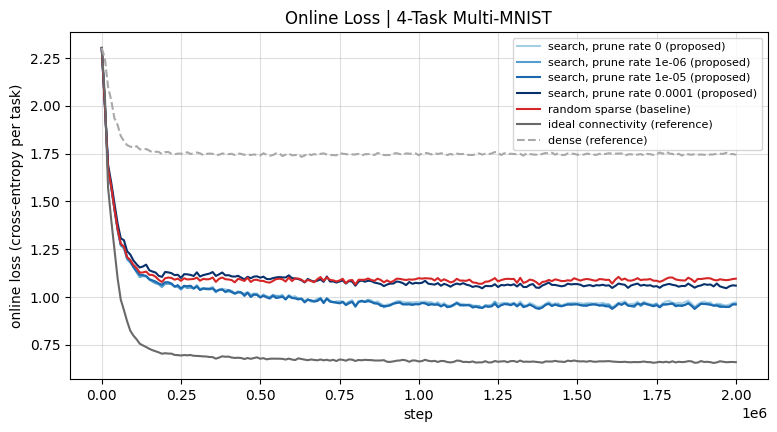

search, prune rate 0 (proposed)          0.9655
search, prune rate 1e-06 (proposed)      0.9575
search, prune rate 1e-05 (proposed)      0.9547
search, prune rate 0.0001 (proposed)     1.0583
random sparse (baseline)                 1.0911
ideal connectivity (reference)           0.6594
dense (reference)                        1.7460

Best search: search, prune rate 1e-05 (proposed)
H1, search vs ideal connectivity: +44.8%: failed
H2, search below random sparse: 12.5%: held
Most units alive in any window: 256 of 256


In [10]:
STEPS = 1 + np.arange(N_WINDOWS + 1) * WINDOW
SEARCH_LABELS = list(runs)[:len(PRUNE_RATES)]
COLORS = {**dict(zip(SEARCH_LABELS, plt.cm.Blues(np.linspace(0.35, 1.0, len(PRUNE_RATES))))),
          'random sparse (baseline)': 'tab:red', 'ideal connectivity (reference)': 'dimgray',
          'dense (reference)': 'darkgray'}
STYLES = {'dense (reference)': '--'}

fig, ax = plt.subplots(figsize=(9, 4.5))
for label, res in runs.items():
    ax.plot(STEPS, res['loss'].mean(0), color=COLORS[label], ls=STYLES.get(label, '-'), lw=1.5, label=label)
ax.set(xlabel='step', ylabel='online loss (cross-entropy per task)', title='Online Loss | 4-Task Multi-MNIST')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

final_loss = {label: res['loss'][:, -round(N_WINDOWS * FINAL_FRACTION):].mean() for label, res in runs.items()}
for label, loss in final_loss.items():
    print(f'{label:<40} {loss:.4f}')
best = min(SEARCH_LABELS, key=final_loss.get)
h1 = final_loss[best] / final_loss['ideal connectivity (reference)'] - 1
h2 = 1 - final_loss[best] / final_loss['random sparse (baseline)']
print(f'\nBest search: {best}')
print(f'H1, search vs ideal connectivity: {100 * h1:+.1f}%: {"held" if h1 <= TOLERANCE else "failed"}')
print(f'H2, search below random sparse: {100 * h2:.1f}%: {"held" if h2 > TOLERANCE else "failed"}')
print(f'Most units alive in any window: {max(runs[label]["units"].max() for label in SEARCH_LABELS):.0f} of {MAX_UNITS}')

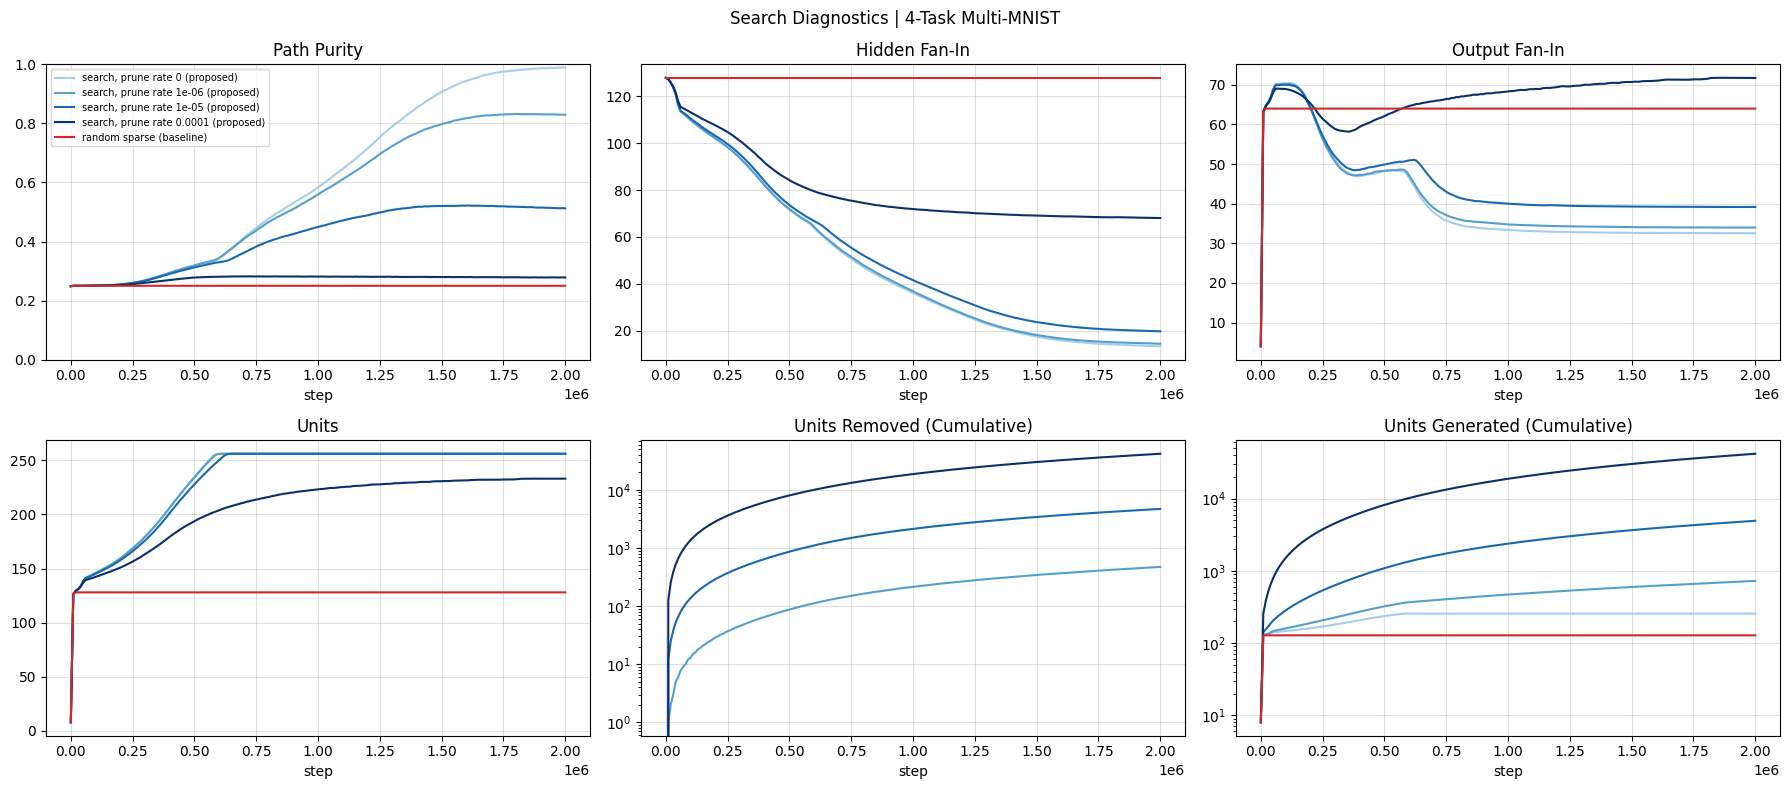

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
steps_per_record = np.append(1, np.full(N_WINDOWS, WINDOW))      # step 1, then every window
cumulative = lambda per_step: np.cumsum(per_step.mean(0) * steps_per_record)
panels = [('Path Purity', lambda r: r['purity'].mean(0)), ('Hidden Fan-In', lambda r: r['fan_in'].mean(0)),
          ('Output Fan-In', lambda r: r['output_fan_in'].mean(0)), ('Units', lambda r: r['units'].mean(0)),
          ('Units Removed (Cumulative)', lambda r: cumulative(r['removed'])),
          ('Units Generated (Cumulative)', lambda r: cumulative(r['added']))]
for ax, (title, value) in zip(axes.flat, panels):
    for label in SEARCH_LABELS + ['random sparse (baseline)']:
        ax.plot(STEPS, value(runs[label]), color=COLORS[label], lw=1.5, label=label)
    ax.set(xlabel='step', title=title)
    ax.grid(alpha=0.4)
axes[0, 0].set_ylim(0, 1)
for ax in axes[1, 1:]:
    ax.set_yscale('log')
axes[0, 0].legend(fontsize=7)
fig.suptitle('Search Diagnostics | 4-Task Multi-MNIST')
fig.tight_layout()
plt.show()

## Results

**L1 = 0.01, connections pruned only** (`UNIT_SEARCH = False`, the outputs above and below):
- Cross-subproblem connections are now pruned: every followed cross-subproblem connection whose step-size fell below
  $\alpha_0/2$ was pruned. Output fan-in falls from 64 to about 17 by 100k steps (16 would mean only
  within-subproblem outputs remain). Hidden fan-in falls from 128 to about 20 by 1M steps and is still falling; that
  is below a unit's 32 within-subproblem inputs, so within-subproblem inputs are pruned too. Path purity rises to
  0.75, still rising.
- L1 at 0.01 cripples learning in every run: ideal connectivity ends at 1.771 (0.642 without L1) and dense learns
  nothing (2.303, chance). H1 passes (search is 27% below ideal connectivity) only because L1 broke the reference.
- Search ends at 1.289, 1.8% above random sparse (1.266): H2 fails.

**Without L1, connections pruned only** (earlier run):
- Search ends at 1.051, 0.7% above random sparse (1.044) and 64% above ideal connectivity (0.642): H1 and H2 fail.
- Output fan-in falls from 64 to about 47.5 and levels off from about 600k steps. Pruning every cross-subproblem
  output connection would take it to 16, and by then most of their step-sizes are below $\alpha_0/2$ (next section),
  so the zero-crossing condition is what stops it: those weights barely move once their step-sizes are small.
- Hidden fan-in falls only from 128 to about 115.5, still falling at 1M steps.
- Path purity stays at 0.25. Three quarters of each unit's inputs belong to other subproblems, so purity cannot rise
  much until input connections are pruned, whatever happens to the outputs.

**Without L1, with unit search** (`UNIT_SEARCH = True`, earlier run):
- **H1 failed.** At its best prune rate ($10^{-5}$), search ends at an online loss of 1.023, 59% above ideal
  connectivity (0.642).
- **H2 held, narrowly.** Search is 2.0% below random sparse (1.044). Prune rates up to $10^{-5}$ make no difference
  (1.023–1.030); $10^{-4}$ and $10^{-3}$ are worse than random sparse (1.077 and 1.196).
- **The search never separates the tasks.** Path purity stays at 0.25, chance for 4 tasks: few connections are pruned.
  Hidden fan-in falls only from 128 to about 117 by 1M steps, starting around 300k, and output fan-in from 64 to about
  53, starting around 200k. Cross-subproblem step-sizes fall below $\alpha_0/2$ only late (next section).
- Dense at this budget has 6 units for 4 tasks and is far worse (1.711).
- At most 144 units were alive at once, so the 256 unit slots never limited the search.

## Step-Sizes Within and Across Subproblems

Random sparse only (search with nothing pruned), to see whether step-sizes separate connections within a unit's
subproblem from those across subproblems. A unit belongs to the subproblem of its shadow weight's output. An input
connection is within the subproblem when its pixel belongs to it, and an output connection when its output does. Biases
are left out. Each curve is the median of $\ln \alpha$ over connections, with the 20th–80th and 5th–95th percentiles
shaded, averaged over windows and then over seeds. The dotted line is the connection-pruning threshold $\alpha_0/2$.

In [12]:
PERCENTILES = (5, 20, 50, 80, 95)


def step_size_percentiles(learner):
    # Percentiles of ln(step-size) over existing connections (biases left out), within and across the unit's
    # subproblem, for input and output connections.
    unit_task = OUTPUT_TASK[learner.shadow_output]
    layers = {'input': (learner.opt.beta['w1'][:, :-1], learner.mask['w1'][:, :-1],
                        INPUT_TASK[learner.sources] == unit_task[:, None]),
              'output': (learner.opt.beta['w2'][:, :-1], learner.mask['w2'][:, :-1],
                         OUTPUT_TASK[:, None] == unit_task[None])}
    percentiles = lambda beta, keep: jnp.nanpercentile(jnp.where(keep, beta, jnp.nan), jnp.array(PERCENTILES))
    return {f'{layer} {kind}': percentiles(beta, exists & (within if kind == 'within' else ~within))
            for layer, (beta, exists, within) in layers.items() for kind in ('within', 'cross')}


step_sizes = run(search_network(), [Config(0.0, False)], extra_record=step_size_percentiles)

5 runs in 168s


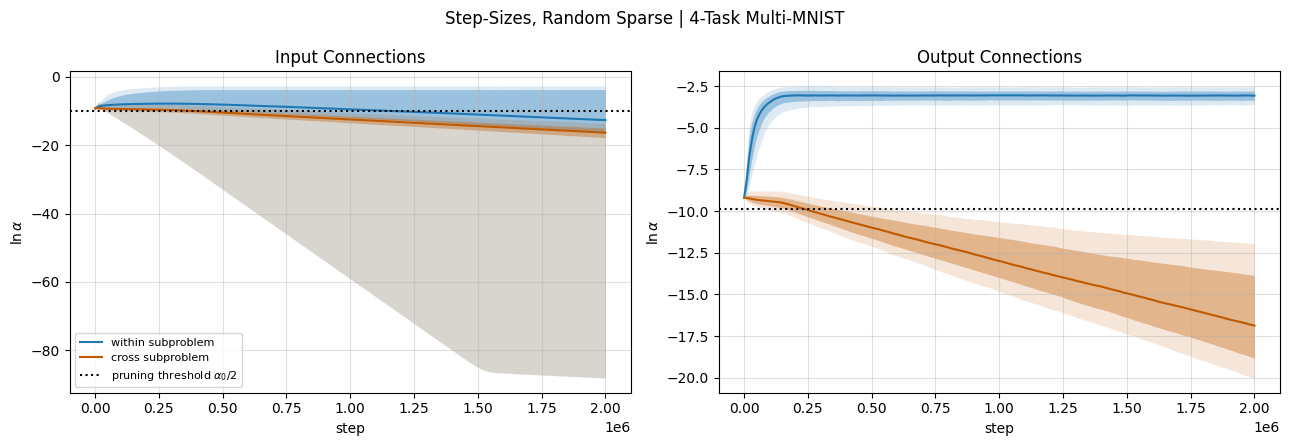

In [13]:
steps = 1 + np.arange(N_WINDOWS + 1) * WINDOW
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, layer in zip(axes, ('input', 'output')):
    for kind, color in [('within', '#1f77b4'), ('cross', '#c05a00')]:
        p = step_sizes[f'{layer} {kind}'][0].mean(0)          # (step 1 + window, percentile)
        ax.fill_between(steps, p[:, 0], p[:, 4], color=color, alpha=0.15, lw=0)
        ax.fill_between(steps, p[:, 1], p[:, 3], color=color, alpha=0.35, lw=0)
        ax.plot(steps, p[:, 2], color=color, lw=1.5, label=f'{kind} subproblem')
    ax.axhline(np.log(INIT_STEP_SIZE / 2), color='black', ls=':', label=r'pruning threshold $\alpha_0/2$')
    ax.set(xlabel='step', ylabel=r'$\ln \alpha$', title=f'{layer.capitalize()} Connections')
    ax.grid(alpha=0.4)
axes[0].legend(fontsize=8)
fig.suptitle('Step-Sizes, Random Sparse | 4-Task Multi-MNIST')
fig.tight_layout()
plt.show()

## Cross-Subproblem Weights Below the Pruning Threshold

Connections pruned only (`UNIT_SEARCH = False`), so the units of the first fill keep their slots and connections can be
followed. To see what happens to cross-subproblem connections whose step-sizes fall below $\alpha_0/2$, 200
random input-connection slots and 200 random output-connection slots of those units are followed in every seed, as means
over 200-step windows. From the ones that are cross-subproblem connections whose step-size fell below $\alpha_0/2$, 20
per layer, drawn at random over seeds, are plotted: the weight and $\ln \alpha$, up to pruning (×).

In [14]:
assert not UNIT_SEARCH                       # followed slots must keep their connections
N_TRACKED, TRACK_WINDOWS = 200, NUM_STEPS // 200     # connections followed per layer, and 200-step windows
FILLED_UNITS = BUDGET // UNIT_COST                   # the first fill takes slots 0 to FILLED_UNITS - 1
input_slot = np.unravel_index(np.random.default_rng(0).choice(FILLED_UNITS * FAN_IN, N_TRACKED, replace=False),
                              (FILLED_UNITS, FAN_IN))                                     # (unit, input weight)
output_slot = np.unravel_index(np.random.default_rng(1).choice(N_OUTPUTS * FILLED_UNITS, N_TRACKED, replace=False),
                               (N_OUTPUTS, FILLED_UNITS))                                 # (output, unit)


def tracked_connections(learner):
    # Weight, ln(step-size), whether it exists, and whether it is cross-subproblem, for each followed connection.
    unit_task = OUTPUT_TASK[learner.shadow_output]
    unit, k = input_slot
    output, unit_out = output_slot
    layers = {'input': ('w1', input_slot, INPUT_TASK[learner.sources[unit, k]] != unit_task[unit]),
              'output': ('w2', output_slot, OUTPUT_TASK[output] != unit_task[unit_out])}
    return {f'{layer} {name}': value for layer, (key, slot, cross) in layers.items()
            for name, value in [('w', learner.w[key][slot]), ('beta', learner.opt.beta[key][slot]),
                                ('exists', learner.mask[key][slot]), ('cross', cross)]}


tracked = run(search_network(), [Config(0.0, True)], extra_record=tracked_connections, n_windows=TRACK_WINDOWS)

AssertionError: 

input: 407 followed cross-subproblem connections fell below the threshold, 407 of them pruned by the end
output: 325 followed cross-subproblem connections fell below the threshold, 323 of them pruned by the end


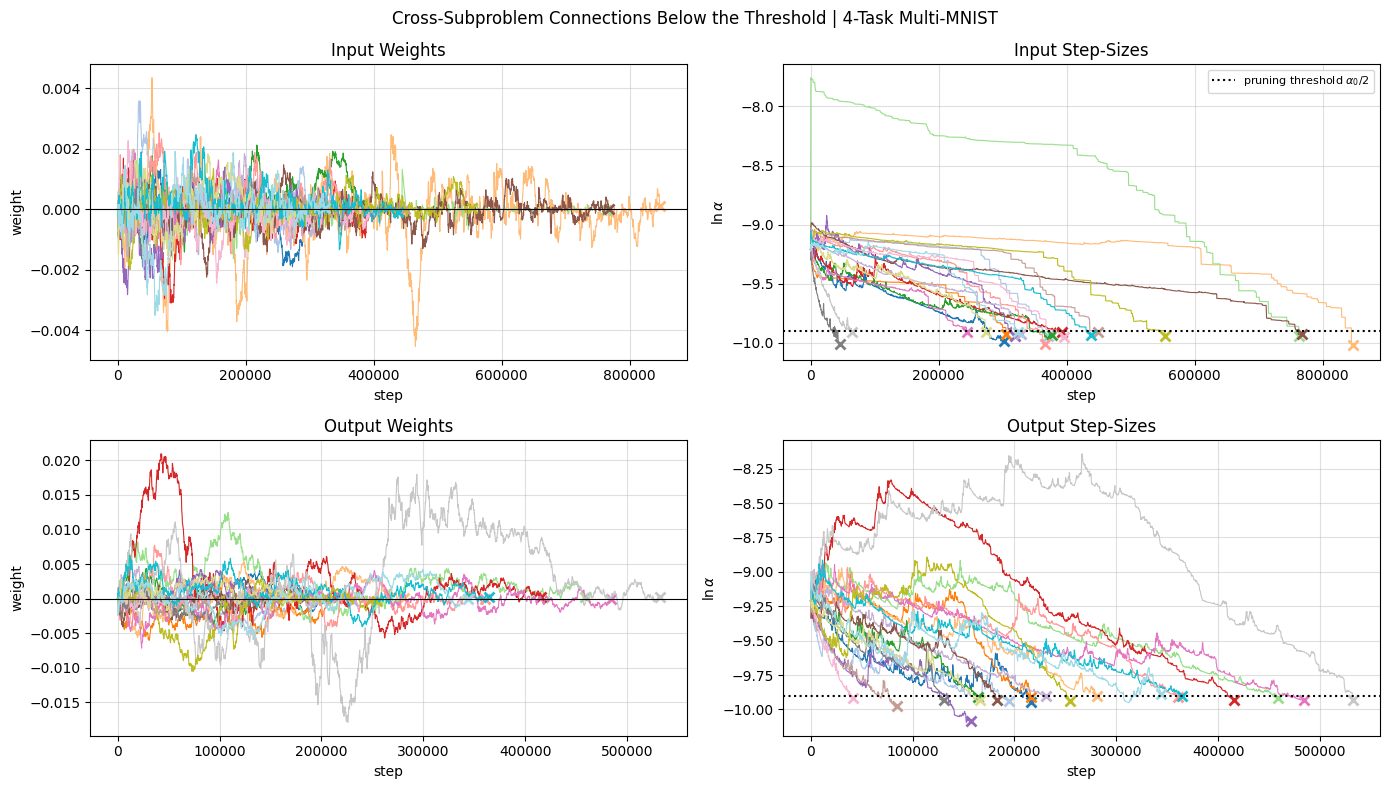

In [ ]:
track_steps = 1 + np.arange(TRACK_WINDOWS + 1) * (NUM_STEPS // TRACK_WINDOWS)
threshold = np.log(INIT_STEP_SIZE / 2)
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for row, layer in zip(axes, ('input', 'output')):
    w, beta, exists, cross = (tracked[f'{layer} {name}'][0] for name in ('w', 'beta', 'exists', 'cross'))
    alive = exists == 1                                                   # existed for the whole window
    below = cross[:, -1].astype(bool) & ((beta < threshold) & alive).any(1)  # (seed, connection)
    candidates = np.argwhere(below)
    picks = candidates[np.random.default_rng(2).choice(len(candidates), min(20, len(candidates)), replace=False)]
    pruned = ~exists[:, -1].astype(bool)
    print(f'{layer}: {len(candidates)} followed cross-subproblem connections fell below the threshold, '
          f'{pruned[below].sum()} of them pruned by the end')
    for color, (seed, j) in zip(plt.cm.tab20(np.arange(20)), picks):
        last = np.flatnonzero(alive[seed, :, j]).max()
        for ax, values in zip(row, (w, beta)):
            ax.plot(track_steps[:last + 1], values[seed, :last + 1, j], color=color, lw=0.8)
            if pruned[seed, j]:
                ax.plot(track_steps[last], values[seed, last, j], 'x', color=color, ms=7, mew=2)
    row[0].axhline(0, color='black', lw=0.8)
    row[1].axhline(threshold, color='black', ls=':', label=r'pruning threshold $\alpha_0/2$')
    row[0].set(ylabel='weight', title=f'{layer.capitalize()} Weights')
    row[1].set(ylabel=r'$\ln \alpha$', title=f'{layer.capitalize()} Step-Sizes')
    for ax in row:
        ax.set_xlabel('step')
        ax.grid(alpha=0.4)
axes[0, 1].legend(fontsize=8)
fig.suptitle('Cross-Subproblem Connections Below the Threshold | 4-Task Multi-MNIST')
fig.tight_layout()
plt.show()